*Draft for review.*

# The georvq Sentinel-2 codec (release s2-v1)

Sentinel-2 Level-1C products come from ESA as SAFE directories, one per
100 km tile, holding 13 bands of uint16 DN on three grids: four bands
at 10 m (10980 x 10980 px), six at 20 m and three at 60 m, about 400 to
750 MB of JPEG 2000 band images per product. The s2-v1 release codes
each product as one Zarr store of about 53 MB that can be read at 9
rates, from 0.28 to 3.17 bits per 10 m pixel, by window, over HTTP.
The reader returns uint16 DN on each band's own grid, with the
product's CRS, transform and nodata, and the store keeps the rest of
the SAFE product, so that a SAFE directory can be written back from it
for tools that read L1C products.

This notebook opens a coded product, compares its reconstructions with
the source at several rates, measures what reads cost in bytes,
requests and time, computes NDVI from source and reconstruction, writes
a SAFE product back from the store, and applies the optional deblocker.
Release details are on the model card
(`earth-compress/georvq-s2-v1` on Hugging Face), and the store layout
in `docs/GEORVQ_ZARR.md`.

## Configuration

`DATA_ROOT` holds the coded stores (`{product}.georvq.zarr`) and their
index. It can be a local directory or an HTTP URL, and points at the
published sample on Hugging Face, or, while `STAGED` is set, at a local
copy of the sample before it is uploaded. `STORAGE_OPTIONS` go to
fsspec when the stores are read by URL, for example a token for a
private repository. `SOURCE_ROOT` holds the source SAFE products, used
here only for comparison.

Each store's header records where its product came from: the
product's entry in the Copernicus Data Space Ecosystem (CDSE)
catalogue, which anyone can read and which gives the product's size
and checksums. Downloading the product itself from CDSE needs a free
CDSE account, so the notebook does not download it. To run the
comparisons with `STAGED = False`, download the product the cell below
prints, unzip it into `SOURCE_ROOT` and rerun. The section on read
times reads the same product's band images from Google Cloud's public
copy of the Sentinel-2 archive, which needs no account.

The codec weights are not in the stores. On the first pixel read,
`georvq.open` finds the bundle the store's header names: in
`$GEORVQ_S2_BUNDLE`, in the cache at `~/.cache/georvq/bundles/<bitstream_id>/`,
or by downloading the decoder-only bundle from the Hugging Face
release (`decoder/` in `earth-compress/georvq-s2-v1`, 108 MB). While
`STAGED` is set the release is not on Hugging Face yet, so the
configuration cell points `$GEORVQ_S2_BUNDLE` at the staged bundle.
On a machine with a GPU the torch backend uses it; everything below
also runs on CPU (a 1080 px window takes about 2 s to decode on 32 CPU
threads, a whole product about 4 minutes).

In [1]:
import os
from rasterio.windows import Window

# ---- configuration: the only cell that names locations ----
# STAGED = True reads the sample staged on cirrus before upload; set it to
# False to read the published sample and model from Hugging Face.
STAGED = True
if STAGED:
    DATA_ROOT = "/data/georvq-releases/s2-v1/sample"
    # local SAFE products, in the CDSE layout <year>/<month>/<day>/<name>.SAFE
    SOURCE_ROOT = "/mnt/raid/data/s2get/Sentinel-2/MSI/L1C"
    # the model repository is not uploaded yet: decode with the staged bundle
    os.environ["GEORVQ_S2_BUNDLE"] = "/data/georvq-releases/s2-v1/bundle"
    DEBLOCKER = "/data/georvq-releases/s2-v1/hf/model/deblocker/deblocker.pt"
else:
    DATA_ROOT = "https://huggingface.co/datasets/earth-compress/georvq-s2-v1-sample/resolve/main"
    # the SAFE product downloaded from CDSE (free account) and unzipped here
    SOURCE_ROOT = os.path.expanduser("~/sentinel-2")
    DEBLOCKER = None                  # downloaded from earth-compress/georvq-s2-v1 when used
STORAGE_OPTIONS = None    # e.g. {"headers": {"Authorization": "Bearer <token>"}}
# Google Cloud's public copy of the Sentinel-2 archive, read in the timing section
SOURCE_REMOTE = "https://storage.googleapis.com/gcp-public-data-sentinel-2/tiles"

PRODUCT = "S2A_MSIL1C_20250531T100051_N0511_R122_T33TTG_20250531T104927"   # Rome and the Lazio coast
# one 1080 px block of the 10 m grid (540 px at 20 m, 180 px at 60 m), at the mouth of the Tiber
WINDOW = Window(col_off=6840, row_off=6840, width=1080, height=1080)

# Speed section: with a local DATA_ROOT, the store is served through a
# range server that adds the latency and throughput measured to Google
# Cloud Storage; with a URL, the hosted store is read as it is.
SIMULATE_REMOTE = not DATA_ROOT.startswith(("http://", "https://"))

In [2]:
import sys, time, tempfile, urllib.request, json, glob, io, shutil, textwrap
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, ListedColormap
from matplotlib.patches import Rectangle
import rasterio
import rasterio.windows
from rasterio.warp import transform_bounds

import pyarrow.parquet as pq
import georvq
from georvq.inference.store_codec import quality_value
from georvq.inference.records import Trace
import ae_demo_http

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.titlesize": 9.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "normal", "legend.frameon": False})
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300",
    "#6250d6", "#e34948")
GREY, INK = "#8a8984", "#52514e"
GRID_COLOURS = {"10m": BLUE, "20m": ORANGE, "60m": AQUA}
FACTORS = {"10m": 1, "20m": 2, "60m": 6}


REMOTE = DATA_ROOT.startswith(("http://", "https://"))


def data_url(product):
    return f"{DATA_ROOT}/{product}.georvq.zarr"


def open_product(product, **kw):
    return georvq.open(data_url(product), storage_options=STORAGE_OPTIONS if REMOTE else None, **kw)


def safe_dir(product):
    """The local SAFE directory of a product, flat under SOURCE_ROOT or in
    the CDSE layout <year>/<month>/<day>/<name>.SAFE."""
    d = product.split("_")[2]
    for p in (f"{SOURCE_ROOT}/{product}.SAFE", f"{SOURCE_ROOT}/{d[:4]}/{d[4:6]}/{d[6:8]}/{product}.SAFE"):
        if os.path.isdir(p):
            return p
    raise FileNotFoundError(f"{product}.SAFE is not under {SOURCE_ROOT}; download it from CDSE "
                            "(see the configuration section) and unzip it there")


def remote_safe(product):
    """The product's folder in Google Cloud's public Sentinel-2 bucket."""
    t = product.split("_")[5]                     # T33TTG
    return f"{SOURCE_REMOTE}/{t[1:3]}/{t[3]}/{t[4:6]}/{product}.SAFE"


# the product index, read once: store sizes and the bytes of whole-product reads
idx_path = f"{DATA_ROOT}/s2_georvq_index.parquet"
if REMOTE:
    req = urllib.request.Request(idx_path, headers=(STORAGE_OPTIONS or {}).get("headers", {}))
    index = pq.read_table(io.BytesIO(urllib.request.urlopen(req).read()))
else:
    index = pq.read_table(idx_path)


def product_row(product):
    return next(r for r in index.to_pylist() if r["product_id"] == product)


def store_size(product):
    r = product_row(product)
    return r["store_bytes"] + r["metadata_bytes"]


# zarr-python makes the requests, so they are counted by a local server
# between it and DATA_ROOT, which forwards each one and records it
if REMOTE:
    METER, meter, _ = ae_demo_http.serve(upstream=DATA_ROOT,
                                         headers=(STORAGE_OPTIONS or {}).get("headers"))
else:
    METER, meter, _ = ae_demo_http.serve(root=DATA_ROOT)


def metered(product):
    """The store's URL through the recording server."""
    return f"{METER}/{product}.georvq.zarr"


def win_tuple(w):
    """A rasterio Window of the 10 m grid as ((row0, row1), (col0, col1))."""
    return ((int(w.row_off), int(w.row_off + w.height)), (int(w.col_off), int(w.col_off + w.width)))


def read_source(product, window=None, bands=None, base=None):
    """{grid: uint16 (bands, rows, cols)} of the source band images, for a
    window of the 10 m grid (None: the whole product), from the local SAFE
    or from `base`, a URL prefix of the SAFE folder."""
    files = ds.source_meta["safe"]["band_files"]
    root = base or safe_dir(product)
    out = {}
    for g in ds.grids:
        f = FACTORS[g]
        names = ds.grid(g).descriptions if bands is None else [b for b in ds.grid(g).descriptions if b in bands]
        if not names:
            continue
        w = None if window is None else Window(window.col_off // f, window.row_off // f,
                                               window.width // f, window.height // f)

        def one(b):
            with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_NUM_THREADS="ALL_CPUS"):
                with rasterio.open(f"{root}/{files[b]}") as s:
                    return s.read(1, window=w)
        with ThreadPoolExecutor(len(names)) as ex:
            out[g] = np.stack(list(ex.map(one, names)))
    return out


def rmse(a, b, valid=None):
    """RMSE in DN over all bands of a grid (valid pixels only, if given)."""
    d = a.astype(np.float64) - b.astype(np.float64)
    if valid is not None:
        d = d[:, valid]
    return float(np.sqrt(np.mean(d * d)))


class Stretch:
    """Three bands of DN as RGB, each stretched between its 1st and 99th
    percentile in the image it is fitted on, with a gamma of 1/1.6."""
    def fit(self, a):
        x = a.reshape(3, -1)
        x = x[:, (x > 0).all(0)].astype(np.float64)
        self.lo, self.hi = np.percentile(x, [1, 99], axis=1)
        return self

    def __call__(self, a):
        x = (a.astype(np.float64) - self.lo[:, None, None]) / (self.hi - self.lo)[:, None, None]
        return np.moveaxis(np.clip(x, 0, 1) ** (1 / 1.6), 0, -1)


def corners(transform, h, w):
    xs, ys = zip(*[transform * (c, r) for c in (0, w) for r in (0, h)])
    return min(xs), min(ys), max(xs), max(ys)


def show(ax, img, transform, ticks=True, **kw):
    """imshow north-up in projected km."""
    h, w = img.shape[:2]
    x0, y0, x1, y1 = corners(transform, h, w)
    im = ax.imshow(img, extent=[x0 / 1e3, x1 / 1e3, y0 / 1e3, y1 / 1e3], **kw)
    if ticks:
        ax.set_xlabel("easting (km)")
        ax.set_ylabel("northing (km)")
    else:
        ax.set_xticks([]); ax.set_yticks([])
    return im


def lonlat(crs, transform, h, w):
    w_, s_, e_, n_ = transform_bounds(crs, "EPSG:4326", *corners(transform, h, w))
    ns = lambda v: f"{abs(v):.2f}°{'N' if v >= 0 else 'S'}"
    ew = lambda v: f"{abs(v):.2f}°{'E' if v >= 0 else 'W'}"
    return f"{ns(s_)} to {ns(n_)}, {ew(w_)} to {ew(e_)}"


def mb(n):
    return f"{n / 1e6:,.2f} MB"


def show_photo(fig, quality=90):
    """Show a figure made mostly of images as JPEG, which is a quarter
    of the size of PNG for them and keeps the notebook small."""
    from IPython.display import Image, display
    buf = io.BytesIO()
    fig.savefig(buf, format="jpeg", dpi=plt.rcParams["figure.dpi"], pil_kwargs={"quality": quality})
    plt.close(fig)
    display(Image(buf.getvalue()))

## Opening a store

`georvq.open` opens the store with zarr-python, which reads the
group's zarr.json with one request: the georeferencing, the codec
header and the metadata of every array. The dataset it returns has the
attributes of a rasterio dataset (`crs`, `transform`, `width`,
`height`, `count`, `dtypes`, `nodata`, `profile`, `descriptions`,
`block_windows()`) for one of the product's three grids, the 10 m grid
unless another is asked for, and its `read` takes the same `window`
argument, plus `quality`, the rate to decode at.

In [3]:
path = data_url(PRODUCT)
ds = open_product(PRODUCT)
meter.clear()
georvq.open(metered(PRODUCT))
open_req, open_bytes = len(meter.events), sum(e["bytes"] for e in meter.events)
attrs = ds.reader.group.attrs

print(f"{'store':<12}{path}")
print(f"{'product':<12}{ds.product['id']}, {ds.product['spacecraft']}, "
      f"sensed {ds.product['sensing_start'][:16]}, baseline {ds.product['processing_baseline']}")
print(f"{'source':<12}{ds.product['source']}")
print(f"{'crs':<12}{attrs['proj:code']} ({ds.crs.to_string()})")
print(f"{'grids':<12}{', '.join(ds.grids)}")
print(f"{'size':<12}{ds.width} x {ds.height} px, {ds.count} bands of {ds.dtypes[0]} "
      f"({', '.join(ds.descriptions)}), nodata {ds.nodata}")
print(f"{'transform':<12}{tuple(ds.transform)[:6]}")
print(f"{'extent':<12}{lonlat(ds.crs, ds.transform, ds.height, ds.width)}")
print(f"{'codec':<12}bitstream {ds.header['codec']['bitstream_id']}, "
      f"decoder {ds.header['codec']['decoder_id']}, release {ds.header['codec']['release']['name']}")
print(f"{'quality':<12}{ds.header['quality']['name']}: {', '.join(ds.header['quality']['stats'])}")
print(f"{'licence':<12}{ds.header['licence']['attribution']} ({ds.header['licence']['name']})")
asset_sizes = {k: ds.assets.info(k)["size"] for k in ds.assets}
print(f"{'assets':<12}{', '.join(f'{k} ({mb(n)})' for k, n in asset_sizes.items())}")
print(f"{'opened with':<12}{open_req} request, {mb(open_bytes)}")

store       /data/georvq-releases/s2-v1/sample/S2A_MSIL1C_20250531T100051_N0511_R122_T33TTG_20250531T104927.georvq.zarr
product     S2A_MSIL1C_20250531T100051_N0511_R122_T33TTG_20250531T104927, Sentinel-2A, sensed 2025-05-31T10:00, baseline 05.11
source      https://catalogue.dataspace.copernicus.eu/odata/v1/Products(1993a370-2a1d-4797-ae51-8efb53ed017e)
crs         EPSG:32633 (EPSG:32633)
grids       10m, 20m, 60m
size        10980 x 10980 px, 4 bands of uint16 (B02, B03, B04, B08), nodata 0
transform   (10.0, 0.0, 199980.0, 0.0, -10.0, 4700040.0)
extent      41.41°N to 42.43°N, 11.35°E to 12.72°E
codec       bitstream 9bfbc0c72d526ad7, decoder e2309f95ff0d5cb4, release s2-v1
quality     rmse_dn: rmse_10m, rmse_20m, rmse_60m
licence     Contains modified Copernicus Sentinel data 2025 (Copernicus Sentinel data terms)
assets      safe_meta (2.18 MB)
opened with 1 request, 0.04 MB


The header lists the rates the store supports. A rate is a depth tuple:
how many residual levels of each of the two tiers to decode (coarse,
one vector per 36 px window; fine, one vector per 60 m pixel, 6 px of
the 10 m grid). Every rung keeps all eight coarse levels. `bits_px`
counts every bit read per 10 m pixel, the transmitted window mean and
standard deviation of each band included, and `whole-product MB` is
what reading the entire product at that rung fetches. The RMSE columns
come from the store's quality array, which holds, for every 36 px
window and every rung, the RMSE in DN of each grid's bands measured
when the product was encoded. They are pooled here over the product's
valid pixels, without decoding anything.

In [4]:
rb = {r["rung"]: r["bytes"] for r in product_row(PRODUCT)["rungs"]}
n_r = len(ds.rungs)
gh = gw = ds.product_height // ds.window_px
qh = ds.header["quality"]
qv = quality_value(ds.quality_codes(0, gh, 0, gw), qh["scale"], qh["offset"]).reshape(gh, gw, len(ds.grids), n_r)
valid10 = ds.dataset_mask() > 0
W = ds.window_px


def window_counts(f):
    """Valid pixels of each 36 px window on the grid of factor f."""
    v = valid10.reshape(gh, W, gw, W).transpose(0, 2, 1, 3)
    if f > 1:
        v = v.reshape(gh, gw, W // f, f, W // f, f).all((3, 5))
    return v.sum((2, 3)).astype(np.float64)


pooled = {g: np.sqrt((window_counts(FACTORS[g])[..., None] * qv[:, :, i] ** 2).sum((0, 1))
                     / window_counts(FACTORS[g]).sum())
          for i, g in enumerate(ds.grids)}
ladder = pd.DataFrame([{"rung": "-".join(map(str, r["tuple"])),
                        "bits/window": r["bits_window"],
                        "bits/px": round(r["bits_px"], 3),
                        "whole-product MB": round(rb["-".join(map(str, r["tuple"]))] / 1e6, 2),
                        **{f"RMSE {g} (DN)": round(pooled[g][k], 1) for g in ds.grids}}
                       for k, r in enumerate(ds.header["rungs"])])
band_bytes = sum(os.path.getsize(f"{safe_dir(PRODUCT)}/{p}")
                 for p in ds.source_meta["safe"]["band_files"].values())
print(f"coded store {mb(store_size(PRODUCT))}, source band images {mb(band_bytes)}, "
      f"ratio {band_bytes / store_size(PRODUCT):.0f} to 1")
ladder.set_index("rung").T

coded store 52.84 MB, source band images 568.56 MB, ratio 11 to 1


rung,8-0,8-1,8-2,8-3,8-4,8-5,8-6,8-7,8-8
bits/window,360.000,828.000,1296.00,1764.000,2232.000,2700.000,3168.000,3636.000,4104.000
bits/px,0.278,0.639,1.00,1.361,1.722,2.083,2.444,2.806,3.167
whole-product MB,4.190,9.680,15.16,20.650,26.140,31.630,37.120,42.610,48.100
RMSE 10m (DN),164.700,118.400,94.90,81.700,73.100,66.800,62.000,58.200,55.200
RMSE 20m (DN),176.900,111.500,82.80,68.400,59.700,53.700,49.400,46.200,43.600
RMSE 60m (DN),20.200,11.200,8.10,6.600,5.600,5.000,4.400,4.000,3.600


## The three grids

The decoder produces the three grids together, so they come from the
same records. The dataset `georvq.open` returns shows the 10 m grid,
and `ds.grid("20m")` and `ds.grid("60m")` are datasets of the other
two, sharing its reader and codec, each with its own shape, transform,
band names and windows. `ds.read_grids` decodes a region of all three
at once and returns them in a dict. A window passed to `read_grids` is
on the 10 m grid, and each grid's array covers the pixels of that grid
the window touches. Reading the three grids one after another decodes
the records three times, so `read_grids` is the cheaper way to get
more than one.

Nodata is 0, as in L1C. The store keeps one validity mask on the 10 m
grid, and a 20 or 60 m pixel is valid when every 10 m pixel it covers
is. All eight products of the sample are fully valid, so this notebook
has no counterpart of the AlphaEarth notebook's section on partial
tiles.

In [5]:
for g in ds.grids:
    d = ds.grid(g)
    print(f"{g}: {d.width} x {d.height} px, bands {', '.join(d.descriptions)}, "
          f"pixel {d.res[0]:.0f} m, window {ds.window_px // FACTORS[g]} px")

rgb_win = ds.read([3, 2, 1], window=WINDOW, quality="8-4")              # B04 B03 B02 of the 10 m grid
w20 = Window(WINDOW.col_off // 2, WINDOW.row_off // 2, WINDOW.width // 2, WINDOW.height // 2)
swir_win = ds.grid("20m").read([6, 4, 1], window=w20, quality="8-4")    # B12 B8A B05
t = time.perf_counter()
grids = ds.read_grids(win_tuple(WINDOW), quality="8-4")
print(f"read_grids at 8-4 in {time.perf_counter() - t:.1f} s on {getattr(ds.codec, 'device', 'cpu')}: "
      + ", ".join(f"{g} {a.shape}" for g, a in grids.items()))
print("read_grids equals the separate reads:",
      np.array_equal(grids["10m"][[2, 1, 0]], rgb_win), np.array_equal(grids["20m"][[5, 3, 0]], swir_win))

10m: 10980 x 10980 px, bands B02, B03, B04, B08, pixel 10 m, window 36 px
20m: 5490 x 5490 px, bands B05, B06, B07, B8A, B11, B12, pixel 20 m, window 18 px
60m: 1830 x 1830 px, bands B01, B09, B10, pixel 60 m, window 6 px


read_grids at 8-4 in 2.1 s on cpu: 10m (4, 1080, 1080), 20m (6, 540, 540), 60m (3, 180, 180)
read_grids equals the separate reads: True True


## What the products look like

The figures show three bands of a grid as red, green and blue,
stretched between their 1st and 99th percentiles. True colour is B04,
B03 and B02, and the false-colour view is B08, B04 and B03 (near
infrared, red and green), in which vegetation is red. The product
overview below comes from the source's own overviews; the window on the
right is stretched by the source window, and the same stretch is
applied to its reconstruction, so equal colours mean equal DN.

decoded 10m (4, 1080, 1080), 20m (6, 540, 540), 60m (3, 180, 180) uint16 in 2.0 s on cpu


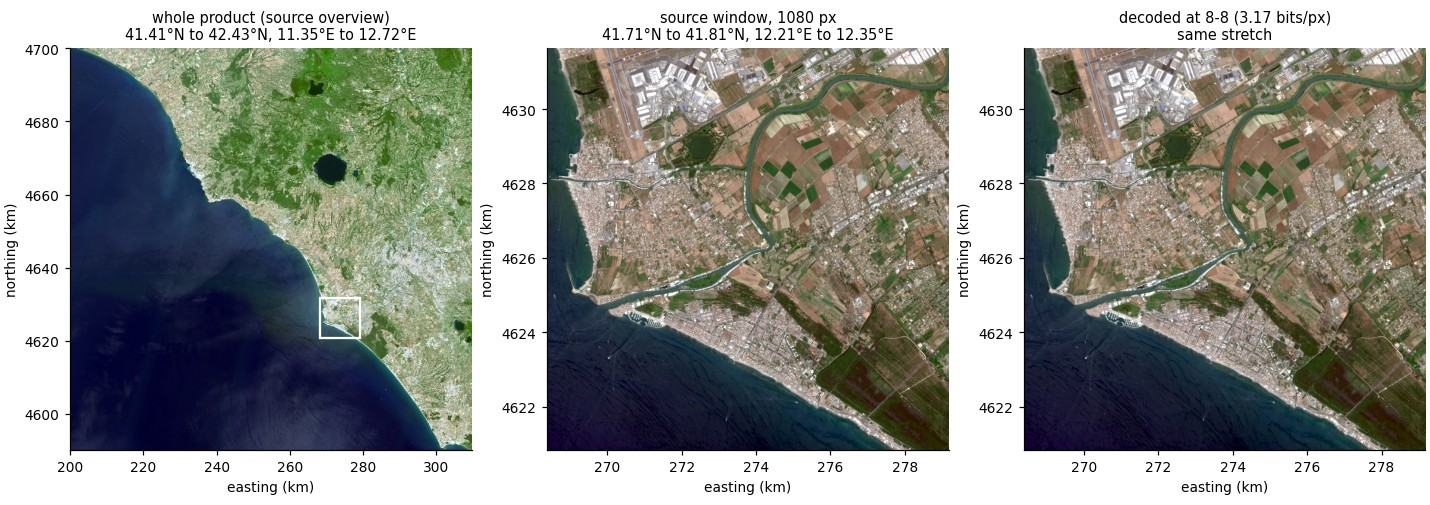

In [6]:
src = read_source(PRODUCT, WINDOW)                               # {grid: (bands, rows, cols)}
files = ds.source_meta["safe"]["band_files"]
with rasterio.open(f"{safe_dir(PRODUCT)}/{files['B02']}") as s:
    ov_t = s.transform * s.transform.scale(s.width / 1098, s.height / 1098)
ov = np.stack([rasterio.open(f"{safe_dir(PRODUCT)}/{files[b]}").read(1, out_shape=(1098, 1098))
               for b in ("B04", "B03", "B02")])

t = time.perf_counter()
full = ds.read_grids(win_tuple(WINDOW))                          # quality=None: full depth, 8-8
print(f"decoded {', '.join(f'{g} {a.shape}' for g, a in full.items())} {full['10m'].dtype} "
      f"in {time.perf_counter() - t:.1f} s on {getattr(ds.codec, 'device', 'cpu')}")

TRUE, FALSE = [2, 1, 0], [3, 2, 1]                              # rows of the 10 m grid: B04 B03 B02, B08 B04 B03
st_true, st_false = Stretch().fit(src["10m"][TRUE]), Stretch().fit(src["10m"][FALSE])
win_t = rasterio.windows.transform(WINDOW, ds.transform)

fig, ax = plt.subplots(1, 3, figsize=(13, 4.6), constrained_layout=True)
show(ax[0], Stretch().fit(ov)(ov), ov_t)
x0, y0, x1, y1 = corners(win_t, WINDOW.height, WINDOW.width)
ax[0].add_patch(Rectangle((x0 / 1e3, y0 / 1e3), (x1 - x0) / 1e3, (y1 - y0) / 1e3,
                          fill=False, ec="white", lw=1.5))
ax[0].set_title(f"whole product (source overview)\n{lonlat(ds.crs, ds.transform, ds.height, ds.width)}")
show(ax[1], st_true(src["10m"][TRUE]), win_t)
ax[1].set_title(f"source window, 1080 px\n{lonlat(ds.crs, win_t, 1080, 1080)}")
show(ax[2], st_true(full["10m"][TRUE]), win_t)
ax[2].set_title(f"decoded at 8-8 ({ds.header['rungs'][-1]['bits_px']:.2f} bits/px)\nsame stretch")
show_photo(fig)

## The rate ladder

The cell below decodes the window at every rung and scores each against
the source by the RMSE in DN of each grid's bands. The figure shows a
360 px crop at five rungs: the coarse tier alone (`8-0`), and one, two,
four and eight fine levels on top (`8-1`, `8-2`, `8-4`, `8-8`), in true
and false colour, with the per-pixel RMSE of the four 10 m bands below
on a log scale.

In [7]:
LADDER = ["8-0", "8-1", "8-2", "8-4", "8-8"]
dec, scores = {}, []
t_all = time.perf_counter()
for r in ds.header["rungs"]:
    q = "-".join(map(str, r["tuple"]))
    a = ds.read_grids(win_tuple(WINDOW), quality=q)
    scores.append({"rung": q, "bits_px": r["bits_px"], **{g: rmse(a[g], src[g]) for g in ds.grids}})
    if q in LADDER:
        dec[q] = a
scores = pd.DataFrame(scores).set_index("rung")
print(f"{n_r} decodes of the window in {time.perf_counter() - t_all:.1f} s")
scores.loc[LADDER].style.format({"bits_px": "{:.3f}", "10m": "{:.1f}", "20m": "{:.1f}", "60m": "{:.1f}"})

9 decodes of the window in 16.6 s


,bits_px,10m,20m,60m
rung,,,,
8-0,0.278,255.4,257.9,33.7
8-1,0.639,184.0,163.4,18.7
8-2,1.000,148.0,123.4,13.3
8-4,1.722,114.5,90.3,9.4
8-8,3.167,86.6,65.9,6.1


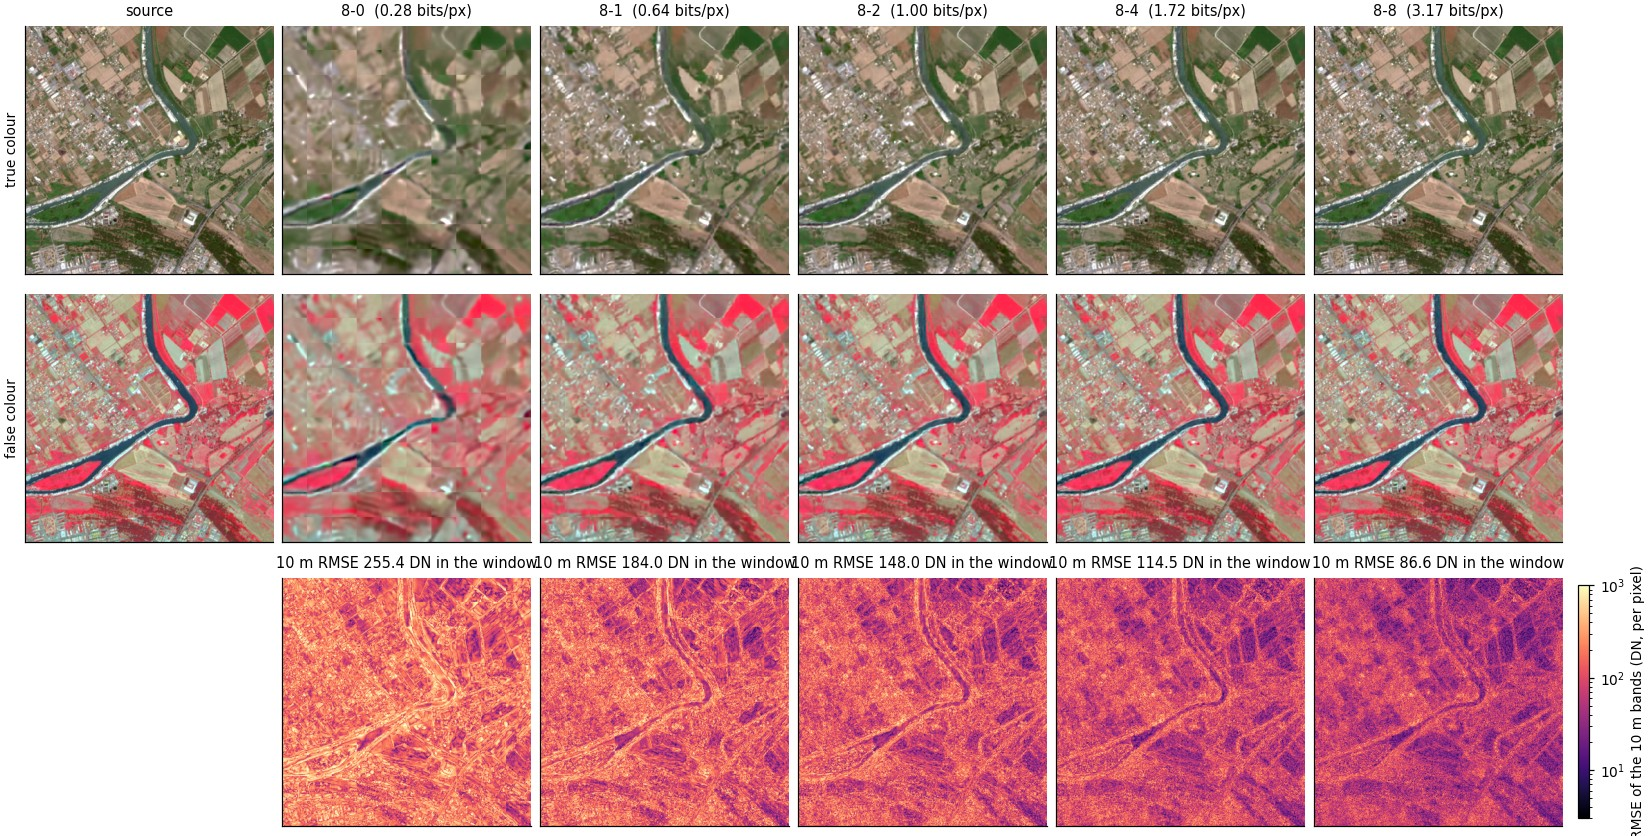

In [8]:
crop = np.s_[360:720, 360:720]          # rows and columns of the window
crop_t = rasterio.windows.transform(Window(WINDOW.col_off + 360, WINDOW.row_off + 360, 360, 360),
                                    ds.transform)
fig, ax = plt.subplots(3, 6, figsize=(15, 7.6), constrained_layout=True)
ref10 = src["10m"][(slice(None),) + crop]
show(ax[0, 0], st_true(ref10[TRUE]), crop_t, ticks=False)
show(ax[1, 0], st_false(ref10[FALSE]), crop_t, ticks=False)
ax[0, 0].set_title("source")
ax[0, 0].set_ylabel("true colour"); ax[1, 0].set_ylabel("false colour")
ax[2, 0].axis("off")
norm = LogNorm(3, 1000)
for k, q in enumerate(LADDER, 1):
    d10 = dec[q]["10m"][(slice(None),) + crop]
    show(ax[0, k], st_true(d10[TRUE]), crop_t, ticks=False)
    show(ax[1, k], st_false(d10[FALSE]), crop_t, ticks=False)
    ax[0, k].set_title(f"{q}  ({scores.loc[q, 'bits_px']:.2f} bits/px)")
    e = np.sqrt(((d10.astype(np.float64) - ref10) ** 2).mean(0))
    im = show(ax[2, k], np.maximum(e, 1), crop_t, ticks=False, cmap="magma", norm=norm)
    ax[2, k].set_title(f"10 m RMSE {scores.loc[q, '10m']:.1f} DN in the window")
fig.colorbar(im, ax=ax[2, :], shrink=0.9, label="RMSE of the 10 m bands (DN, per pixel)", pad=0.01)
show_photo(fig)

The curve puts the 9 rungs on one axis, one colour per grid. The solid
lines are measured on this window here. The dashed lines cover the
whole product and come from the store's quality array (the RMSE
columns of the table above), so they need no decoding. Every rung
carries the 360 bits per window of the coarse tier and the statistics,
and each fine level adds 468 bits, which gives the even spacing in
rate.

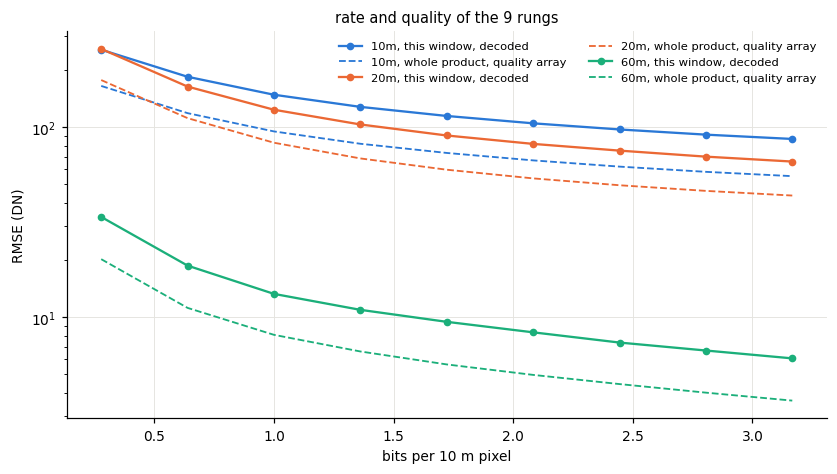

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 4.2), constrained_layout=True)
bpp = scores["bits_px"].values
for g in ds.grids:
    ax.plot(bpp, scores[g], "-o", color=GRID_COLOURS[g], ms=4, lw=1.5, label=f"{g}, this window, decoded")
    ax.plot(bpp, pooled[g], "--", color=GRID_COLOURS[g], lw=1.2, label=f"{g}, whole product, quality array")
ax.set_yscale("log")
ax.set_xlabel("bits per 10 m pixel"); ax.set_ylabel("RMSE (DN)")
ax.grid(True, which="major", color="#e4e3df", lw=0.6)
ax.legend(fontsize=7.5, ncol=2)
ax.set_title("rate and quality of the 9 rungs")
plt.show()

## A window and the whole product

A read decodes only the windows it touches, so reading a 1080 px block
costs about 1% of reading the product. The cell below reads the whole
product at 8-4 with `read_grids` and no window, compares each grid
with the source, and maps the RMSE of the 10 m bands per 36 px window
as measured here and as the quality array records it. The two maps
differ only by the quantisation of the quality codes (steps of 7.5%)
and by the small differences between decodes made on different devices
or in different batches, since the quality values were measured when
the product was encoded.

whole product at 8-4 decoded in 195 s on cpu; source band images read in 3 s


                      10m   20m  60m
RMSE, decoded here   73.1  59.6  5.6
RMSE, quality array  73.1  59.7  5.6


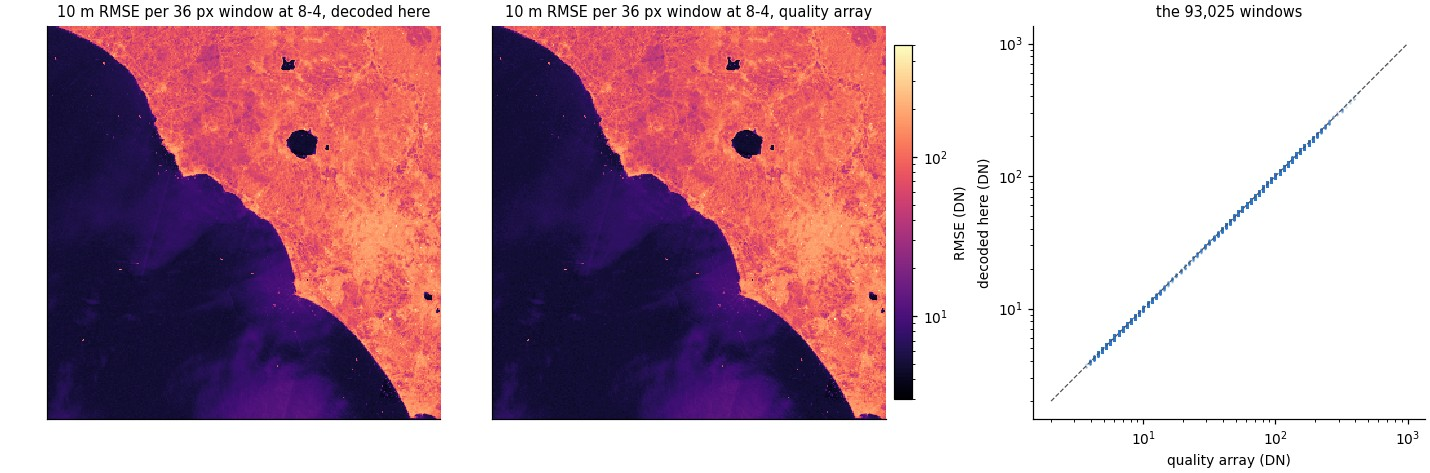

In [10]:
t = time.perf_counter()
whole = ds.read_grids(quality="8-4")
t_whole = time.perf_counter() - t
t = time.perf_counter()
src_whole = read_source(PRODUCT)
t_src = time.perf_counter() - t
k84 = list(scores.index).index("8-4")
print(f"whole product at 8-4 decoded in {t_whole:.0f} s on {getattr(ds.codec, 'device', 'cpu')}; "
      f"source band images read in {t_src:.0f} s")
print(pd.DataFrame({g: {"RMSE, decoded here": rmse(whole[g], src_whole[g], ds.grid(g).dataset_mask() > 0),
                        "RMSE, quality array": pooled[g][k84]} for g in ds.grids}).round(1))

e10 = sum((whole["10m"][i].astype(np.float32) - src_whole["10m"][i]) ** 2 for i in range(4)) / 4
e10 = np.sqrt(e10.reshape(gh, W, gw, W).mean((1, 3)))
fig, ax = plt.subplots(1, 3, figsize=(13, 4.3), constrained_layout=True,
                       gridspec_kw={"width_ratios": [1, 1, 0.9]})
norm = LogNorm(3, 500)
x0, y0, x1, y1 = corners(ds.transform, ds.height, ds.width)
for a, img, title in ((ax[0], e10, "decoded here"), (ax[1], qv[:, :, 0, k84], "quality array")):
    im = a.imshow(np.maximum(img, 1), cmap="magma", norm=norm, interpolation="nearest",
                  extent=[x0 / 1e3, x1 / 1e3, y0 / 1e3, y1 / 1e3])
    a.set_xticks([]); a.set_yticks([])
    a.set_title(f"10 m RMSE per 36 px window at 8-4, {title}")
fig.colorbar(im, ax=ax[:2], shrink=0.9, label="RMSE (DN)", pad=0.01)
ax[2].loglog(qv[:, :, 0, k84].ravel(), e10.ravel(), ".", ms=1, color=BLUE, alpha=0.3)
ax[2].plot([2, 1000], [2, 1000], color=INK, lw=0.8, ls="--")
ax[2].set_xlabel("quality array (DN)"); ax[2].set_ylabel("decoded here (DN)")
ax[2].set_title(f"the {gh * gw:,} windows")
show_photo(fig)

## What reads cost

Each read below opens the store afresh, so nothing is cached, and counts
the requests zarr-python makes after the open and the bytes they fetch,
as the recording server between it and `DATA_ROOT` sees them. The
source column is what GDAL fetches to read the same pixels from the 13
JPEG 2000 band images, counted the same way through a server in front
of the SAFE directory. The band images are tiled (1024 px tiles at 10
m, 640 px at 20 m and 192 px at 60 m), so GDAL reads only the tiles a
window touches, and every band is a separate file. A product
downloaded from CDSE comes as one zip, so the first read of any part
of it costs the whole download. The three whole-product rows fetch the
records without decoding them, and their source column is the size of
the band images.

In [11]:
def cost(fn, product=PRODUCT):
    with georvq.open(metered(product), codec=ds.codec) as d:
        meter.clear()
        fn(d)
        ev = list(meter.events)
        return len(ev), sum(e["bytes"] for e in ev)


SAFE_HTTP, safe_meter, safe_srv = ae_demo_http.serve(root=safe_dir(PRODUCT))


def src_cost(window):
    safe_meter.clear()
    read_source(PRODUCT, window, base=SAFE_HTTP)
    ev = list(safe_meter.events)
    return sum(e["bytes"] for e in ev)


px = Window(WINDOW.col_off + 540, WINDOW.row_off + 540, 6, 6)       # one 60 m pixel, 6 x 6 at 10 m
reads = [("one 60 m pixel at 8-8", lambda d: d.read_grids(win_tuple(px), quality="8-8"), src_cost(px))]
block_src = src_cost(WINDOW)
for q in ["8-0", "8-2", "8-4", "8-8"]:
    reads.append((f"1080 px block at {q}", lambda d, q=q: d.read_grids(win_tuple(WINDOW), quality=q), block_src))
for q in [(8, 0), (8, 4), (8, 8)]:
    reads.append((f"whole product at {'-'.join(map(str, q))}",
                  lambda d, q=q: d.reader.read(0, gh, 0, gw, depths=list(q)), band_bytes))
safe_srv.shutdown()

costs = pd.DataFrame([dict(zip(("read", "requests", "bytes"), (name,) + cost(fn)), source_bytes=sb)
                      for name, fn, sb in reads]).set_index("read")
costs["source / georvq"] = (costs["source_bytes"] / costs["bytes"]).round(1)
print(f"open: {open_req} request, {mb(open_bytes)} of metadata")
costs

open: 1 request, 0.04 MB of metadata


,requests,bytes,source_bytes,source / georvq
read,,,,
one 60 m pixel at 8-8,10,1926961,25811198,13.4
1080 px block at 8-0,1,167445,46274814,276.4
1080 px block at 8-2,4,609727,46274814,75.9
1080 px block at 8-4,6,1048805,46274814,44.1
1080 px block at 8-8,10,1926961,46274814,24.0
whole product at 8-0,25,4186125,568558210,135.8
whole product at 8-4,126,26143229,568558210,21.7
whole product at 8-8,26,48097129,568558210,11.8


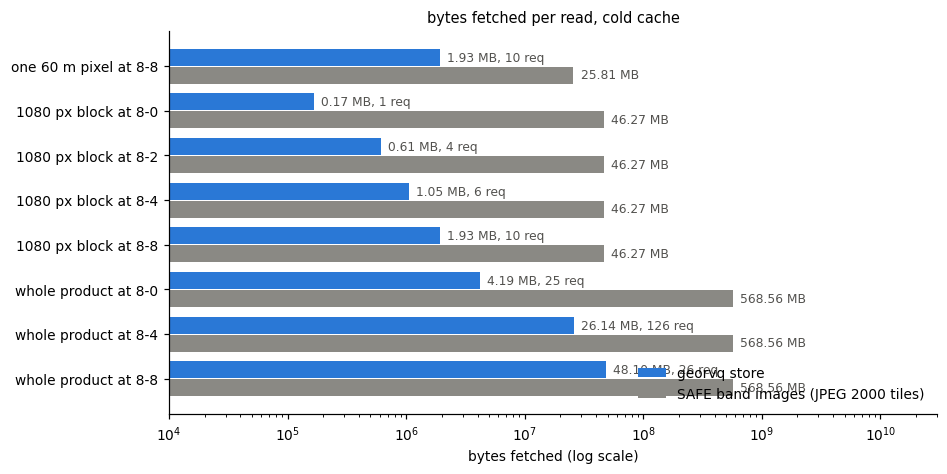

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 4.2), constrained_layout=True)
y = np.arange(len(costs))[::-1]
ax.barh(y + 0.2, costs["bytes"], height=0.38, color=BLUE, label="georvq store")
ax.barh(y - 0.2, costs["source_bytes"], height=0.38, color=GREY, label="SAFE band images (JPEG 2000 tiles)")
for yy, (n, b) in zip(y, zip(costs["requests"], costs["bytes"])):
    ax.text(b * 1.15, yy + 0.2, f"{mb(b)}, {n} req", va="center", fontsize=8, color=INK)
for yy, b in zip(y, costs["source_bytes"]):
    ax.text(b * 1.15, yy - 0.2, mb(b), va="center", fontsize=8, color=INK)
ax.set_yticks(y, costs.index)
ax.set_xscale("log"); ax.set_xlim(1e4, 3e10)
ax.set_xlabel("bytes fetched (log scale)")
ax.legend(loc="lower right")
ax.set_title("bytes fetched per read, cold cache")
plt.show()

## How long a read takes over HTTP

This section times one cold read of the 1080 px block, from
`georvq.open` to the uint16 arrays of the three grids in memory, at
four rungs, and the same block of the 13 band images read from Google
Cloud's public copy of the product with rasterio and GDAL, one thread
per band. The codec is loaded beforehand and reused, so loading the
weights is not timed.

The coded sample is not hosted next to the source, so a fair
comparison needs a stand-in. The first cell measures the latency (time
to first byte of small range requests) and the single-stream
throughput (one 16 MB range request) from this machine to Google Cloud
Storage. With `SIMULATE_REMOTE = True`, the coded store is then served
from a local range server that waits that latency before each response
and limits each response to that throughput. zarr-python makes the
requests and the server records each one; the georvq reader's own
trace records the decode stages. The source read goes through a local
forwarding server that times each GDAL request to Google Cloud;
GDAL's decompression is not separated from its requests and appears as
gaps. With `SIMULATE_REMOTE = False` and `DATA_ROOT` set to a URL, the
same cell reads the hosted store through a forwarding server, with no
simulation.

In [13]:
probe_url = f"{remote_safe(PRODUCT)}/{files['B08']}"
net = ae_demo_http.probe(probe_url, offset=1 << 24)
print(f"latency {net['latency_s'] * 1e3:.0f} ms (median of "
      f"{', '.join(f'{v * 1e3:.0f}' for v in net['ttfb_all_s'])} ms), "
      f"throughput {net['throughput_Bps'] / 1e6:.2f} MB/s over one "
      f"{net['large_bytes'] / 1e6:.0f} MB request")

latency 68 ms (median of 53, 62, 68, 82, 93 ms), throughput 51.20 MB/s over one 17 MB request


In [14]:
SPEED_RUNGS = ["8-0", "8-2", "8-4", "8-8"]
codec = ds.codec
servers = []
if SIMULATE_REMOTE:
    base, rec_g, srv_g = ae_demo_http.serve(root=DATA_ROOT, latency=net["latency_s"],
                                            bandwidth=net["throughput_Bps"])
else:
    base, rec_g, srv_g = ae_demo_http.serve(upstream=DATA_ROOT,
                                            headers=(STORAGE_OPTIONS or {}).get("headers"))
servers.append(srv_g)
speed_url = f"{base}/{PRODUCT}.georvq.zarr"

runs = {}
for q in SPEED_RUNGS:
    tr = Trace()
    rec_g.clear()
    t0 = time.perf_counter()
    with georvq.open(speed_url, codec=codec, trace=tr) as d:
        a = d.read_grids(win_tuple(WINDOW), quality=q)
    # the server's requests in place of the reader's per-array reads
    events = [e for e in tr.events if e["kind"] != "get"] + list(rec_g.events)
    runs[f"georvq {q}"] = {"t0": t0, "t1": time.perf_counter(), "events": events,
                           "bytes": sum(e["bytes"] for e in rec_g.events)}

base_s, rec_s, srv_up = ae_demo_http.serve(upstream=remote_safe(PRODUCT))
servers.append(srv_up)
t0 = time.perf_counter()
a_src = read_source(PRODUCT, WINDOW, base=base_s)
t1 = time.perf_counter()
runs["source JPEG 2000"] = {"t0": t0, "t1": t1, "bytes": sum(e["bytes"] for e in rec_s.events),
                            "events": list(rec_s.events)}
for s_ in servers:
    s_.shutdown()
assert all(np.array_equal(a_src[g], src[g]) for g in ds.grids)
for k, r in runs.items():
    n = sum(e["kind"] == "get" for e in r["events"])
    print(f"{k:<18} {r['t1'] - r['t0']:7.2f} s  {n:4d} requests  {mb(r['bytes'])}")

georvq 8-0            1.81 s     2 requests  0.21 MB
georvq 8-2            2.97 s     5 requests  0.65 MB
georvq 8-4            2.35 s     7 requests  1.09 MB
georvq 8-8            2.61 s    11 requests  1.97 MB
source JPEG 2000     14.89 s   886 requests  46.60 MB


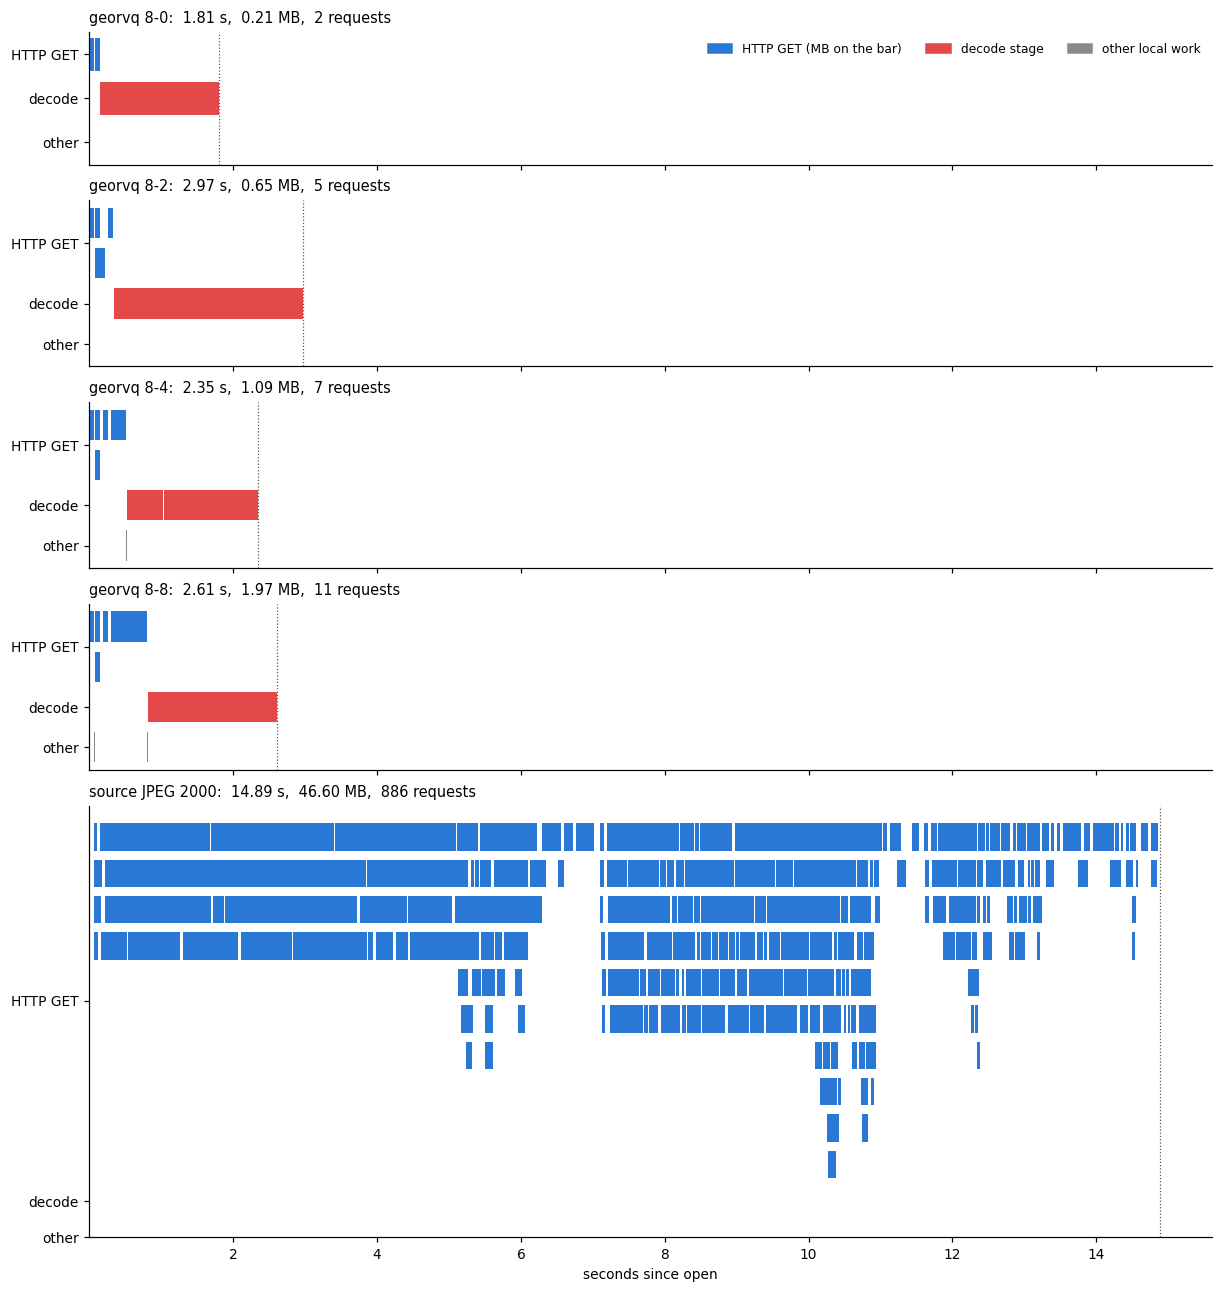

,mean channel (ms),codebook lookup (ms),decoder forward (ms),postprocess (ms)
read,,,,
georvq 8-0,1.5,3.3,1634.1,6.7
georvq 8-2,1.5,4.7,2611.3,7.1
georvq 8-4,1.5,9.5,1785.4,6.8
georvq 8-8,1.4,14.5,1761.8,6.5


In [15]:
COLOURS = {"get": BLUE, "decode": RED, "cpu": GREY}


def lanes(events):
    """Greedy lane assignment so overlapping events do not cover each other."""
    ends, out = [], []
    for e in sorted(events, key=lambda e: e["t0"]):
        for i, end in enumerate(ends):
            if e["t0"] >= end:
                ends[i] = e["t1"]; out.append((i, e)); break
        else:
            ends.append(e["t1"]); out.append((len(ends) - 1, e))
    return out, len(ends)


def gantt(runs, max_lanes=12):
    groups = {k: {kind: lanes([e for e in r["events"] if e["kind"] == kind])
                  for kind in ("get", "decode", "cpu")} for k, r in runs.items()}
    heights = [sum(min(max(n, 1), max_lanes) for _, n in g.values()) + 1 for g in groups.values()]
    t_max = max(r["t1"] - r["t0"] for r in runs.values())
    fig, axes = plt.subplots(len(runs), 1, figsize=(11, 0.32 * sum(heights) + 1.4), sharex=True,
                             gridspec_kw={"height_ratios": heights}, constrained_layout=True)
    for ax, (k, r) in zip(axes, runs.items()):
        row, ticks = 0, []
        for kind in ("get", "decode", "cpu"):
            placed, n = groups[k][kind]
            n = min(n, max_lanes)
            for lane, e in placed:
                lane = lane % max_lanes              # very many parallel requests share lanes
                x0, w = e["t0"] - r["t0"], max(e["t1"] - e["t0"], 1e-3)
                ax.barh(row + lane, w, left=x0, height=0.75, color=COLOURS[kind], lw=0)
                if kind == "get" and w > 0.04 * t_max:
                    ax.text(x0 + w / 2, row + lane, mb(e["bytes"]).replace(" MB", ""), ha="center",
                            va="center", fontsize=6.5, color="white")
            ticks.append((row + (max(n, 1) - 1) / 2, {"get": "HTTP GET", "decode": "decode",
                                                        "cpu": "other"}[kind]))
            row += max(n, 1)
        ax.set_yticks([t for t, _ in ticks], [l for _, l in ticks])
        ax.invert_yaxis()
        ax.set_title(f"{k}:  {r['t1'] - r['t0']:.2f} s,  {mb(r['bytes'])},  "
                     f"{sum(e['kind'] == 'get' for e in r['events'])} requests", loc="left")
        ax.axvline(r["t1"] - r["t0"], color=INK, lw=0.8, ls=":")
    axes[-1].set_xlabel("seconds since open")
    axes[0].legend(handles=[Rectangle((0, 0), 1, 1, color=c) for c in COLOURS.values()],
                   labels=["HTTP GET (MB on the bar)", "decode stage", "other local work"],
                   loc="upper right", ncol=3, fontsize=8)
    plt.show()


gantt(runs)

stages = pd.DataFrame([{**{"read": k}, **{lab: sum(e["t1"] - e["t0"] for e in r["events"]
                                               if e["label"] == lab)
                                           for lab in ("mean channel", "codebook lookup",
                                                       "decoder forward", "postprocess")}}
                       for k, r in runs.items() if k.startswith("georvq")]).set_index("read")
(stages * 1e3).round(1).rename(columns=lambda c: c + " (ms)")

The next cell reads a quarter of the product (5400 px) through the same
server at the same rungs, and splits each read into the time spent
fetching and the time spent decoding.

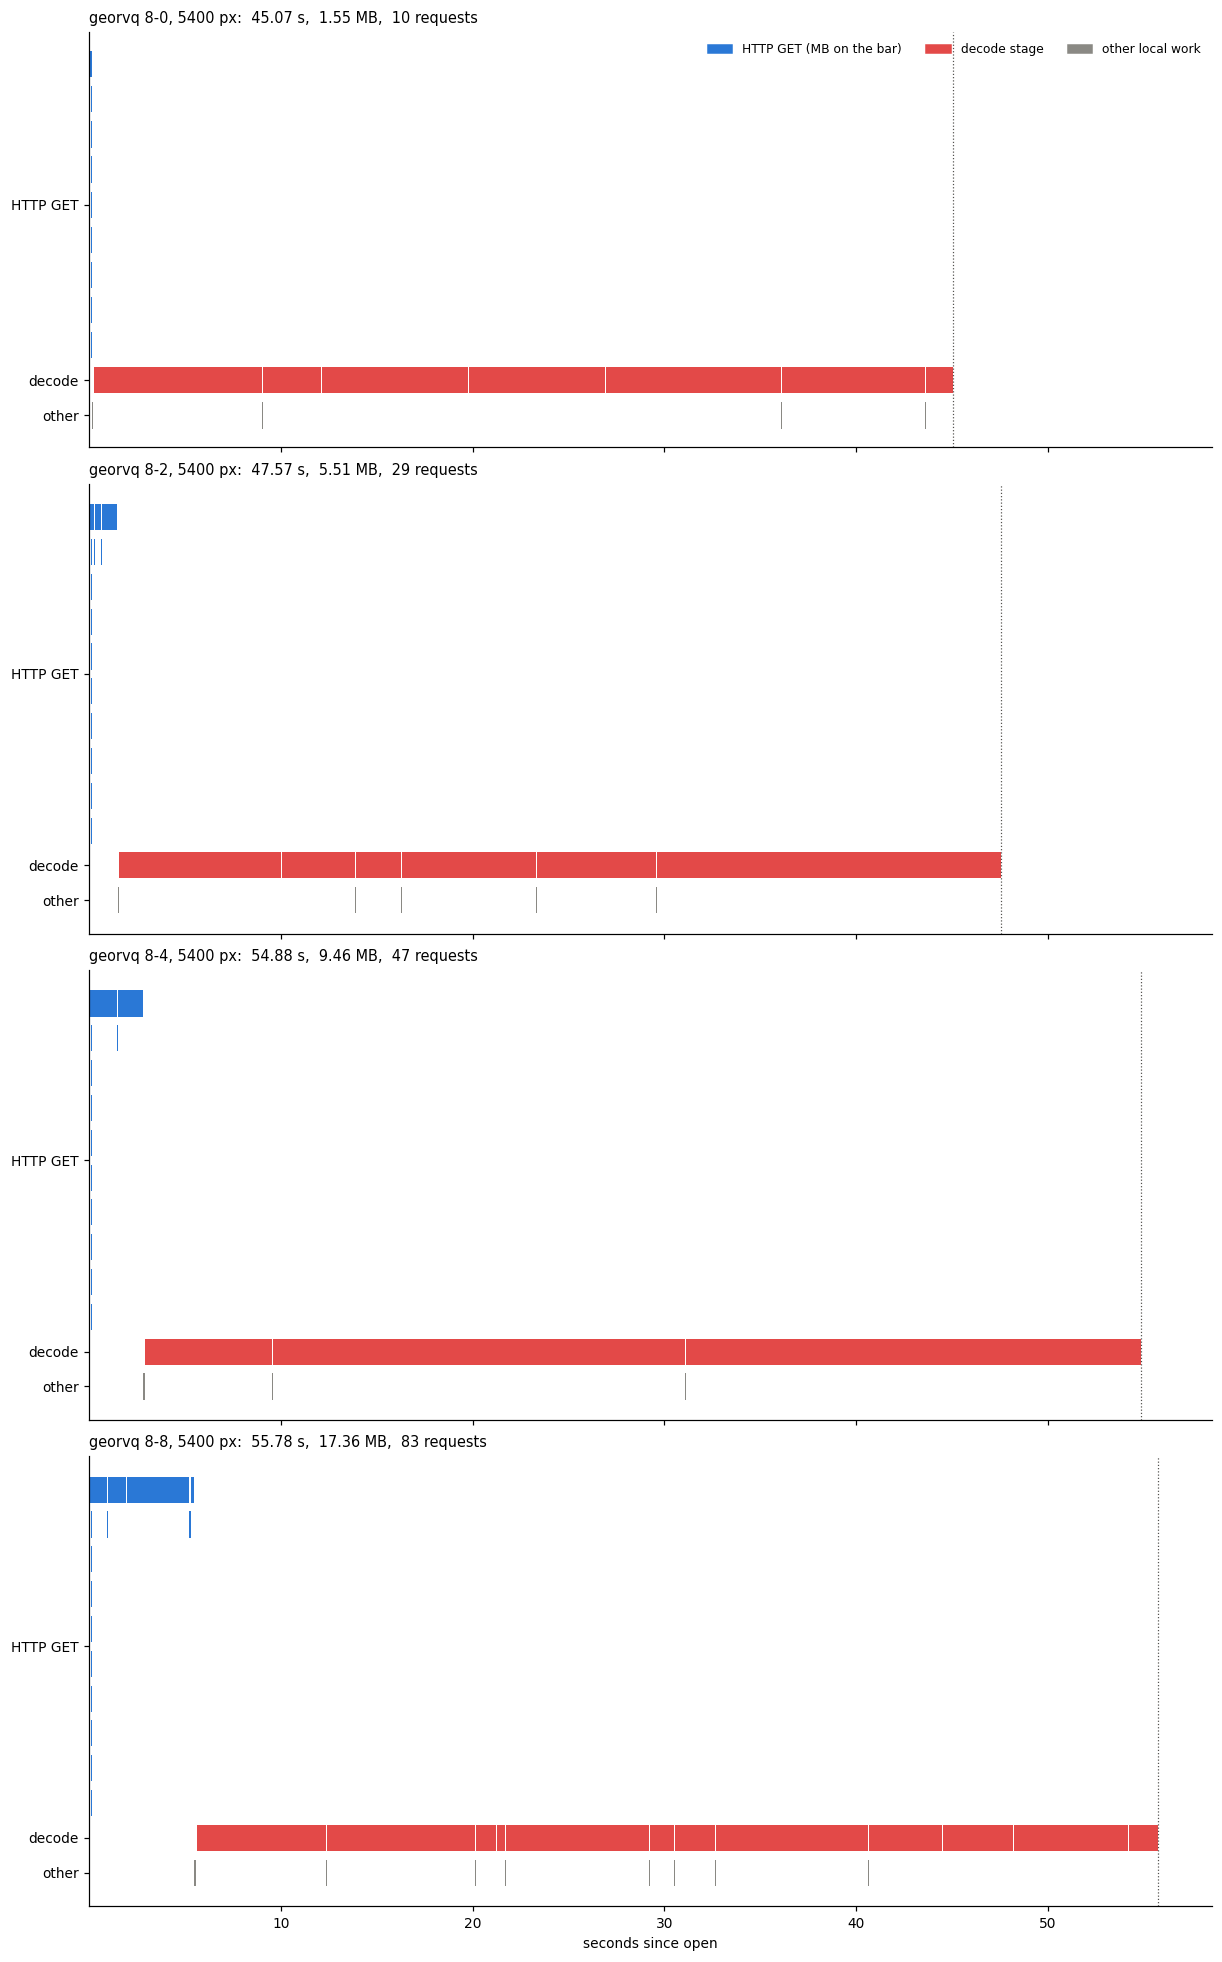

,MB,requests,fetch (s),decode (s),total (s)
read,,,,,
georvq 8-0,0.21,2,0.14,1.65,1.81
georvq 8-2,0.65,5,0.29,2.62,2.97
georvq 8-4,1.09,7,0.43,1.80,2.35
georvq 8-8,1.97,11,0.72,1.78,2.61
"georvq 8-0, 5400 px",1.55,10,0.15,44.61,45.07
"georvq 8-2, 5400 px",5.51,29,1.46,45.78,47.57
"georvq 8-4, 5400 px",9.46,47,2.76,51.75,54.88
"georvq 8-8, 5400 px",17.36,83,5.37,49.97,55.78


In [16]:
WIDE = Window(col_off=5580, row_off=5580, width=5400, height=5400)


def spans(events, kind):
    """Wall-clock time covered by events of one kind (overlaps counted once)."""
    t, end = 0.0, -1e18
    for e in sorted((e for e in events if e["kind"] == kind), key=lambda e: e["t0"]):
        t0 = max(e["t0"], end)
        if e["t1"] > t0:
            t += e["t1"] - t0
        end = max(end, e["t1"])
    return t


if SIMULATE_REMOTE:
    base, rec_g, srv_g = ae_demo_http.serve(root=DATA_ROOT, latency=net["latency_s"],
                                            bandwidth=net["throughput_Bps"])
else:
    base, rec_g, srv_g = ae_demo_http.serve(upstream=DATA_ROOT,
                                            headers=(STORAGE_OPTIONS or {}).get("headers"))
speed_url = f"{base}/{PRODUCT}.georvq.zarr"
wide = {}
for q in SPEED_RUNGS:
    tr = Trace()
    rec_g.clear()
    t0 = time.perf_counter()
    with georvq.open(speed_url, codec=codec, trace=tr) as d:
        d.read_grids(win_tuple(WIDE), quality=q)
    events = [e for e in tr.events if e["kind"] != "get"] + list(rec_g.events)
    wide[f"georvq {q}, 5400 px"] = {"t0": t0, "t1": time.perf_counter(), "events": events,
                                    "bytes": sum(e["bytes"] for e in rec_g.events)}
srv_g.shutdown()
gantt(wide)
pd.DataFrame([{"read": k, "MB": round(r["bytes"] / 1e6, 2),
               "requests": sum(e["kind"] == "get" for e in r["events"]),
               "fetch (s)": round(spans(r["events"], "get"), 2),
               "decode (s)": round(spans(r["events"], "decode"), 2),
               "total (s)": round(r["t1"] - r["t0"], 2)}
              for k, r in {**{k: v for k, v in runs.items() if k.startswith("georvq")},
                           **wide}.items()]).set_index("read")

## Reading to a quality bound

Instead of a rung, `read` accepts a bound on a quality statistic, such
as `quality="rmse_10m<=100"`. The reader looks up each window's measured
errors in the quality array and decodes every window at the cheapest
rung that meets the bound, or at full depth where none does. The map
shows the rung chosen for each window of the product: open sea needs
no fine level, and land needs more the more detail it holds. Within
one read the reader fetches the fine tier at the deepest level any
window in the read needs, so the bytes fetched sit between the ideal
per-window cost and the full-depth cost. Each grid has its own
statistic, so a reader of the 20 m bands can bound `rmse_20m` instead.
The quality values are stored to the nearest step of 7.5%, so a window
read to a bound can come out up to 3.7% above it when decoded, as the
histogram shows.

whole product at rmse_10m<=100: 14.9 MB of records chosen per window, against 47.7 MB at 8-8
this block: 2.03 MB in 11 requests at rmse_10m<=100, against 1.93 MB at 8-8
whole product: 93.0% of windows meet the bound at some rung
windows of the block that meet it at some rung: 72.6%; of those, meeting it when decoded here: 72.0% (worst 103.7 DN)


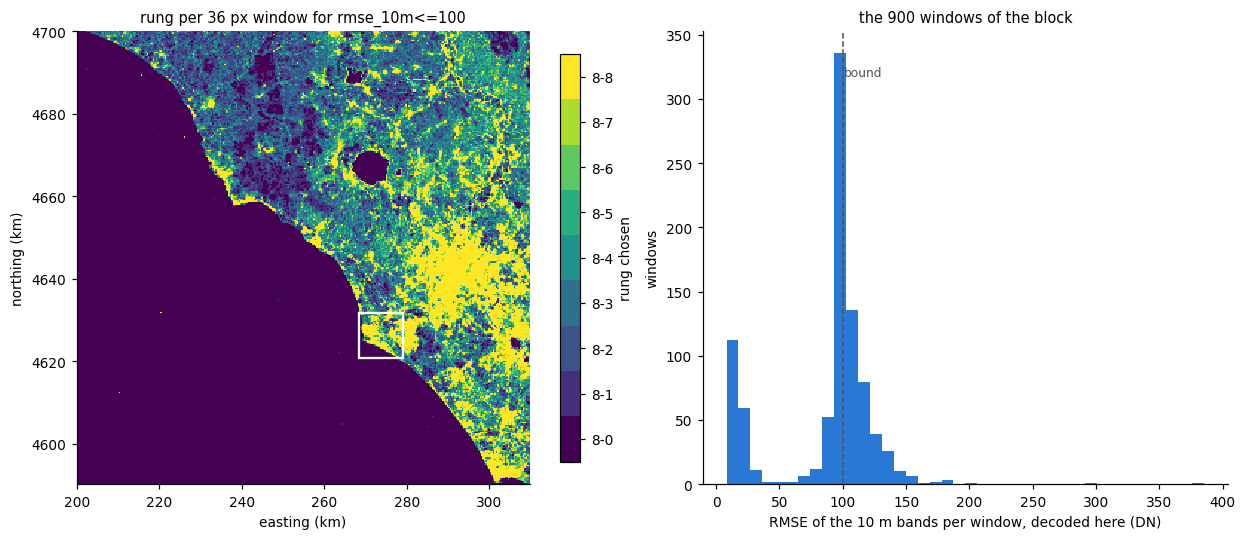

In [17]:
BOUND, LIMIT = "rmse_10m<=100", 100.0
rmap = ds.window_rungs(BOUND)                               # whole product, north-up window grid
bits = np.array([r["bits_window"] for r in ds.header["rungs"]])
names = ["-".join(map(str, r)) for r in ds.rungs]
used = np.unique(rmap)

d_q = cost(lambda d: d.read_grids(win_tuple(WINDOW), quality=BOUND))
a_q = ds.read_grids(win_tuple(WINDOW), quality=BOUND)
nw = WINDOW.width // W
d10 = a_q["10m"].astype(np.float64) - src["10m"]
rmse_w = np.sqrt((d10 ** 2).mean(0).reshape(nw, W, nw, W).mean((1, 3)))

print(f"whole product at {BOUND}: {bits[rmap].sum() / 8 / 1e6:.1f} MB of records chosen per window, "
      f"against {rmap.size * bits[-1] / 8 / 1e6:.1f} MB at 8-8")
print(f"this block: {mb(d_q[1])} in {d_q[0]} requests at {BOUND}, "
      f"against {mb(costs.loc['1080 px block at 8-8', 'bytes'])} at 8-8")
wy0, wx0 = int(WINDOW.row_off) // W, int(WINDOW.col_off) // W
can = (qv[wy0:wy0 + nw, wx0:wx0 + nw, 0, :] <= LIMIT).any(-1)
print(f"whole product: {(qv[:, :, 0, :] <= LIMIT).any(-1).mean():.1%} of windows meet the bound at some rung")
print(f"windows of the block that meet it at some rung: {can.mean():.1%}; of those, meeting it when "
      f"decoded here: {(rmse_w[can] <= LIMIT).mean():.1%} (worst {rmse_w[can].max():.1f} DN)")

cmap = plt.get_cmap("viridis", len(used))
lut = np.zeros(len(ds.rungs), int); lut[used] = np.arange(len(used))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True,
                       gridspec_kw={"width_ratios": [1.15, 1]})
x0, y0, x1, y1 = corners(ds.transform, ds.height, ds.width)
im = ax[0].imshow(lut[rmap], cmap=cmap, vmin=-0.5, vmax=len(used) - 0.5,
                  extent=[x0 / 1e3, x1 / 1e3, y0 / 1e3, y1 / 1e3], interpolation="nearest")
cb = fig.colorbar(im, ax=ax[0], ticks=np.arange(len(used)), shrink=0.9)
cb.ax.set_yticklabels([names[i] for i in used]); cb.set_label("rung chosen")
bx0, by0, bx1, by1 = corners(win_t, WINDOW.height, WINDOW.width)
ax[0].add_patch(Rectangle((bx0 / 1e3, by0 / 1e3), (bx1 - bx0) / 1e3, (by1 - by0) / 1e3,
                          fill=False, ec="white", lw=1.5))
ax[0].set_xlabel("easting (km)"); ax[0].set_ylabel("northing (km)")
ax[0].set_title(f"rung per 36 px window for {BOUND}")
ax[1].hist(rmse_w.ravel(), bins=40, color=BLUE)
ax[1].axvline(LIMIT, color=INK, ls="--", lw=1)
ax[1].text(LIMIT * 1.01, ax[1].get_ylim()[1] * 0.9, "bound", color=INK, fontsize=8)
ax[1].set_xlabel("RMSE of the 10 m bands per window, decoded here (DN)")
ax[1].set_ylabel("windows")
ax[1].set_title(f"the {nw * nw} windows of the block")
plt.show()

## NDVI

A common use of the red and near-infrared bands, computed on the source
window and on reconstructions at four rungs. NDVI is
(B08 - B04) / (B08 + B04) of top-of-atmosphere reflectance, which is
(DN + offset) / 10000, with the offset of each band taken from the
store's header (-1000 DN for products of processing baseline 04.00 and
later, 0 before). The table reports the correlation of each NDVI map
with the source's, its RMSE and 99th percentile absolute difference,
and the share of pixels on the same side of 0.3, a common threshold
for vegetation. The last line repeats the RMSE over the whole product,
from the 8-4 read above.

In [18]:
off = ds.product.get("radio_add_offset") or {}
qv_ = ds.product.get("quantification_value", 10000.0)


def ndvi(g10):
    """NDVI of a 10 m grid (B02 B03 B04 B08); NaN at nodata."""
    red = (g10[2].astype(np.float64) + off.get("B04", 0)) / qv_
    nir = (g10[3].astype(np.float64) + off.get("B08", 0)) / qv_
    with np.errstate(invalid="ignore", divide="ignore"):
        v = (nir - red) / (nir + red)
    v[(g10 == 0).any(0)] = np.nan
    return v


SHOW = ["8-0", "8-2", "8-4", "8-8"]
nd = {"source": ndvi(src["10m"])} | {q: ndvi(dec[q]["10m"]) for q in SHOW}
ok = np.isfinite(nd["source"])
rows = []
for q in SHOW:
    d = (nd[q] - nd["source"])[ok]
    rows.append({"rung": q, "NDVI r": np.corrcoef(nd["source"][ok], nd[q][ok])[0, 1],
                 "RMSE": np.sqrt(np.mean(d * d)), "p99 |diff|": np.quantile(np.abs(d), 0.99),
                 "same side of 0.3": ((nd[q] > 0.3) == (nd["source"] > 0.3))[ok].mean()})
nw_src, nw_dec = ndvi(src_whole["10m"]), ndvi(whole["10m"])
okw = np.isfinite(nw_src)
print(f"whole product at 8-4: NDVI RMSE {np.sqrt(np.nanmean((nw_dec - nw_src)[okw] ** 2)):.4f}, "
      f"same side of 0.3 for {((nw_dec > 0.3) == (nw_src > 0.3))[okw].mean():.2%} of pixels")
pd.DataFrame(rows).set_index("rung").style.format("{:.4f}")

whole product at 8-4: NDVI RMSE 0.0366, same side of 0.3 for 98.01% of pixels


,NDVI r,RMSE,p99 |diff|,same side of 0.3
rung,,,,
8-0,0.8566,0.1661,0.3412,0.8714
8-2,0.9285,0.1169,0.2055,0.9295
8-4,0.9843,0.0533,0.1639,0.9463
8-8,0.9902,0.0422,0.1313,0.9595


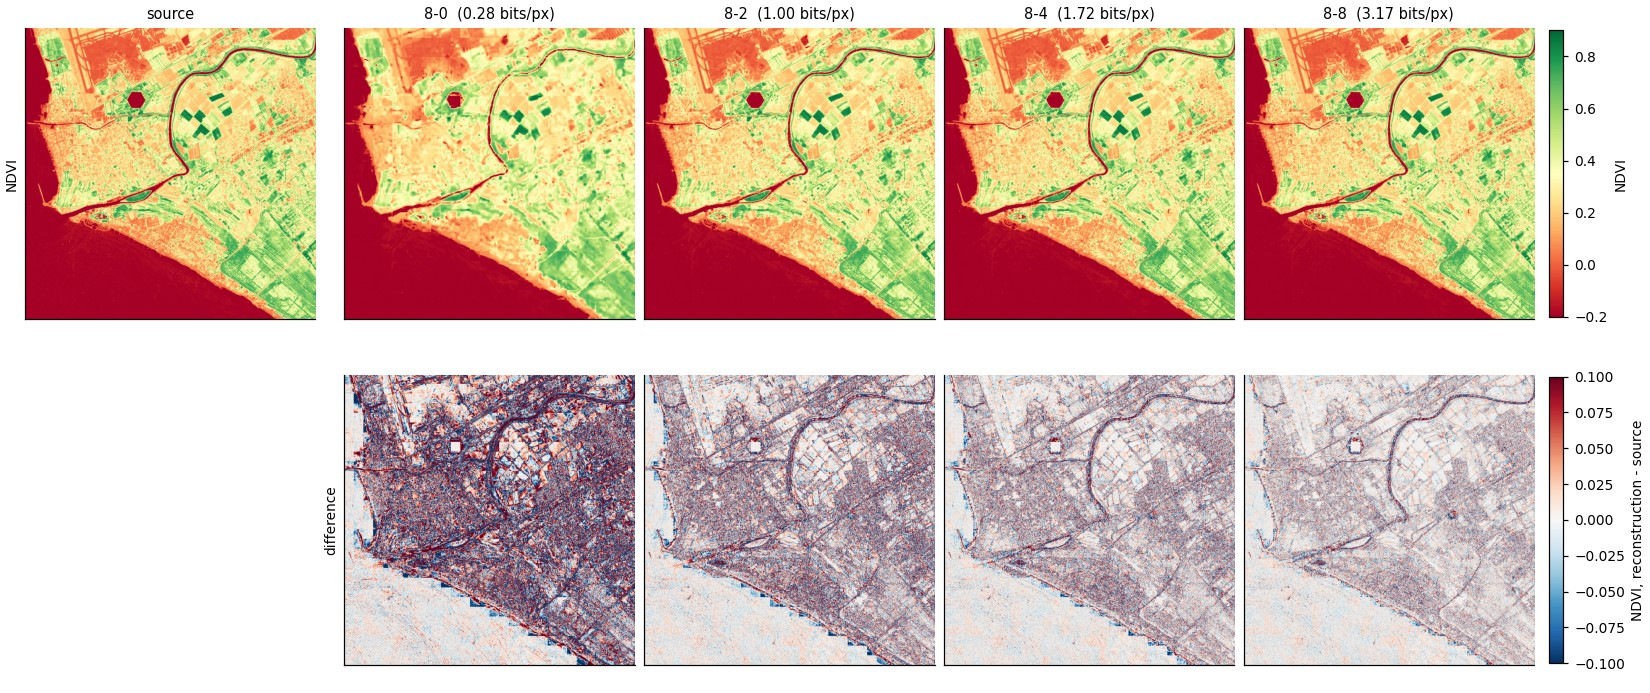

In [19]:
fig, ax = plt.subplots(2, 5, figsize=(15, 6.3), constrained_layout=True)
for j, (k, v) in enumerate(nd.items()):
    im = show(ax[0, j], v, win_t, ticks=False, cmap="RdYlGn", vmin=-0.2, vmax=0.9)
    ax[0, j].set_title(k if k == "source" else f"{k}  ({scores.loc[k, 'bits_px']:.2f} bits/px)")
    if k == "source":
        ax[1, j].axis("off")
        continue
    im2 = show(ax[1, j], v - nd["source"], win_t, ticks=False, cmap="RdBu_r", vmin=-0.1, vmax=0.1)
fig.colorbar(im, ax=ax[0, :], shrink=0.85, pad=0.01, label="NDVI")
fig.colorbar(im2, ax=ax[1, :], shrink=0.85, pad=0.01, label="NDVI, reconstruction - source")
ax[0, 0].set_ylabel("NDVI"); ax[1, 1].set_ylabel("difference")
show_photo(fig)

## The product index

`s2_georvq_index.parquet` has one row per coded store. Its first
columns are the same in every georvq release's index: the store's
path, the product id, the source URL (here the CDSE catalogue entry),
the release, the CRS, the size and bounds in the product's UTM zone,
the footprint in longitude and latitude (`geometry` and its `bbox`),
the codec ids, the store's sizes, and the bytes a whole-product read
fetches at each rung. The columns of the source follow, taken from
each product's metadata: the SAFE name, MGRS tile, relative orbit,
spacecraft, sensing time and processing baseline. It is GeoParquet, so
pyarrow, GeoPandas or DuckDB can query it without opening the coded
stores.

8 products; columns: path, product_id, source_url, release, crs, width, height, bounds, bbox, geometry, bitstream_id, decoder_id, store_bytes, metadata_bytes, quality_bytes, rungs, safe, mgrs_tile, relative_orbit, spacecraft, sensing_start, processing_baseline
in the Europe box, from 2020: ['S2A_MSIL1C_20250531T100051_N0511_R122_T33TTG_20250531T104927.georvq.zarr']
duckdb is not installed; the same query works with read_parquet() in DuckDB


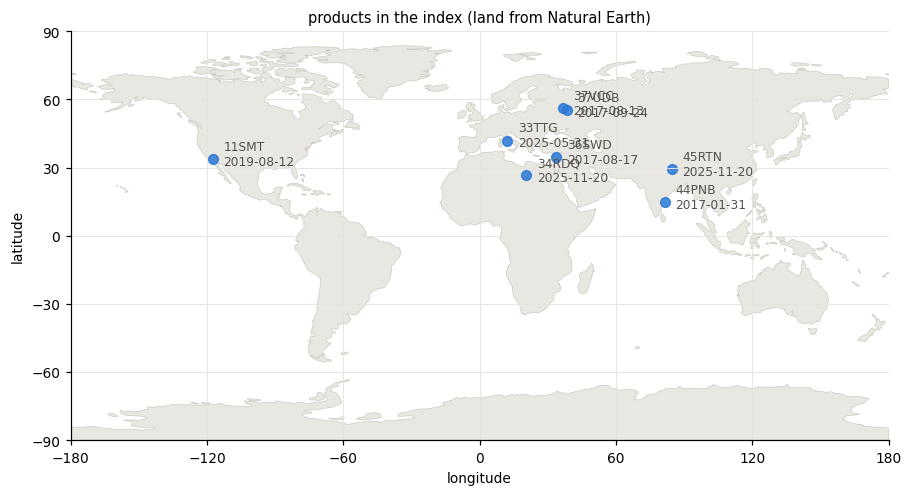

,tile,sensed,baseline,lon,lat,store MB,8-4 MB
0,44PNB,2017-01-31,05.00,81.51,14.88,52.68,26.14
1,37UDB,2017-09-24,05.00,38.28,55.45,53.59,26.14
2,11SMT,2019-08-12,05.00,-117.49,33.84,52.93,26.14
3,33TTG,2025-05-31,05.11,12.04,41.92,52.84,26.14
4,37VCC,2017-08-13,05.00,36.64,56.33,53.58,26.14
5,36SWD,2017-08-17,05.00,33.60,34.75,53.44,26.14
6,45RTN,2025-11-20,05.11,84.47,29.31,53.26,26.14
7,34RDQ,2025-11-20,05.11,20.54,26.63,53.27,26.14


In [20]:
import pyarrow.compute as pc

idx = index                                  # read with the helpers above, from idx_path
print(f"{idx.num_rows} products; columns: {', '.join(idx.column_names)}")


def at(rungs, name):
    return next(r["bytes"] for r in rungs if r["rung"] == name)


bbox = idx["bbox"].to_pylist()
products = pd.DataFrame({
    "tile": idx["mgrs_tile"].to_pylist(),
    "sensed": [t.strftime("%Y-%m-%d") for t in idx["sensing_start"].to_pylist()],
    "baseline": idx["processing_baseline"].to_pylist(),
    "lon": [(b["xmin"] + b["xmax"]) / 2 for b in bbox],
    "lat": [(b["ymin"] + b["ymax"]) / 2 for b in bbox],
    "store MB": [(b + m) / 1e6 for b, m in zip(idx["store_bytes"].to_pylist(),
                                               idx["metadata_bytes"].to_pylist())],
    "8-4 MB": [at(r, "8-4") / 1e6 for r in idx["rungs"].to_pylist()]})

# products whose footprint box intersects a box over Europe, sensed from 2020 on
box = dict(west=-10, south=35, east=30, north=70)
b = pc.struct_field(idx["bbox"], "xmin"), pc.struct_field(idx["bbox"], "xmax")
c = pc.struct_field(idx["bbox"], "ymin"), pc.struct_field(idx["bbox"], "ymax")
sel = idx.filter(pc.and_(pc.and_(pc.and_(pc.greater(b[1], box["west"]), pc.less(b[0], box["east"])),
                                 pc.and_(pc.greater(c[1], box["south"]), pc.less(c[0], box["north"]))),
                         pc.greater_equal(pc.year(idx["sensing_start"]), 2020)))
print(f"in the Europe box, from 2020: {sel['path'].to_pylist()}")
try:
    import duckdb
    print(duckdb.sql(f"select mgrs_tile, sensing_start, store_bytes from read_parquet('{idx_path}') "
                     "order by sensing_start").df())
except ImportError:
    print("duckdb is not installed; the same query works with read_parquet() in DuckDB")

fig, ax = plt.subplots(figsize=(9, 4.4), constrained_layout=True)
try:
    import geopandas as gpd
    land = gpd.read_file("https://naciscdn.org/naturalearth/110m/physical/ne_110m_land.zip")
    land.plot(ax=ax, color="#e9e7e1", edgecolor="#c9c6bd", lw=0.4, zorder=0)
except Exception as e:                       # no geopandas or no network: points only
    print(f"no basemap ({type(e).__name__})")
ax.scatter(products["lon"], products["lat"], s=40, color=BLUE, alpha=0.85)
for _, t in products.iterrows():
    ax.annotate(f"{t['tile']}\n{t['sensed']}", (t["lon"], t["lat"]),
                textcoords="offset points", xytext=(7, -4), fontsize=8, color=INK)
ax.set_xlim(-180, 180); ax.set_ylim(-90, 90)
ax.set_xticks(range(-180, 181, 60)); ax.set_yticks(range(-90, 91, 30))
ax.grid(True, color="#e4e3df", lw=0.6, zorder=-1)
ax.set_aspect("equal")
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
ax.set_title("products in the index (land from Natural Earth)")
plt.show()
products.round(2)

## Writing a SAFE product, and decoding without torch

`reconstruct_safe` (or `georvq s2 reconstruct` on the command line)
writes the SAFE product a store was coded from, with its 13 band
images decoded at one rung or quality bound:

    georvq s2 reconstruct STORE.georvq.zarr out_dir/ --quality 8-4

Every file but the band images comes from the store's `safe_meta`
asset, byte for byte the original's, apart from the true-colour image
TCI, which the store does not keep. The band images are written as
lossless JPEG 2000 with the original's tiling and georeferencing, and
`manifest.safe` gets their new sizes and checksums, loses the entries
of TCI, and gains a comment saying that the product is a
reconstruction. `GEORVQ_RECONSTRUCTION.json` at the product root
records the store, the codec ids and the quality. Tools that read L1C
products can open the result, and below GDAL's SENTINEL2 driver opens
it through rasterio. The product's metadata (`MTD_MSIL1C.xml`) and the
HTML index still list TCI, so GDAL offers a TCI subdataset, which
warns that the file is missing and reads as zeros.

`backend="onnx"` decodes with onnxruntime and numpy from the ONNX
export in the full bundle, without torch, in fp32. On CUDA the torch
backend decodes in bf16 by default, so the comparison below is made
against an fp32 torch decode (`bf16=False`), which is what the torch
backend gives on CPU.

In [21]:
from georvq.s2.v1 import reconstruct_safe

out_dir = tempfile.mkdtemp()
t = time.perf_counter()
root = reconstruct_safe(ds, out_dir, quality="8-4")
t_rec = time.perf_counter() - t

recon_bytes = sum(os.path.getsize(f"{root}/{p}") for p in files.values())
print(f"{root}\nwritten in {t_rec:.0f} s; band images {mb(recon_bytes)} against {mb(band_bytes)} "
      f"in the original")
manifest = open(f"{root}/manifest.safe", encoding="utf-8").read()
note = manifest[manifest.index("<!--"):manifest.index("-->") + 3]
print("\nmanifest.safe:", textwrap.fill(note, 100, subsequent_indent="    "))
marker = json.load(open(f"{root}/GEORVQ_RECONSTRUCTION.json"))
print("\nGEORVQ_RECONSTRUCTION.json:", {k: marker[k] for k in ("bitstream_id", "decoder_id", "rung", "omitted")})

import warnings
with warnings.catch_warnings():
    # the product-level dataset has no geotransform, only its subdatasets do
    warnings.simplefilter("ignore", rasterio.errors.NotGeoreferencedWarning)
    with rasterio.open(f"{root}/MTD_MSIL1C.xml") as mtd:
        subs = mtd.subdatasets
print("\nSENTINEL2 subdatasets:")
for s_ in subs:
    print("   ", s_.replace(root, "<product>"))
with rasterio.open(next(s_ for s_ in subs if ":10m:" in s_)) as s10:
    r10 = s10.read(window=WINDOW)
    print(f"\n10 m subdataset: {s10.driver}, {s10.width} x {s10.height}, {s10.count} bands, "
          f"{s10.crs.to_string()}, transform equal to the store's: {s10.transform == ds.transform}")
    gdal_bands = [d.split(",")[0] for d in s10.descriptions]          # e.g. "B4"
order = [ds.descriptions.index(b if b == "B8A" else f"B{int(b[1:]):02d}") for b in gdal_bands]
print(f"subdataset bands {gdal_bands}")
diff = np.abs(r10.astype(int) - dec["8-4"]["10m"][order].astype(int))
print(f"window read through GDAL against the store's 8-4 read: {(diff == 0).mean():.4%} of values equal, "
      f"largest difference {diff.max()} DN")
shutil.rmtree(out_dir)                 # the product takes about 460 MB; keep it to open in other tools

/tmp/tmpvccsvvjh/S2A_MSIL1C_20250531T100051_N0511_R122_T33TTG_20250531T104927.SAFE
written in 223 s; band images 470.08 MB against 568.56 MB in the original

manifest.safe: <!-- georvq reconstruction: the 13 band images in GRANULE/*/IMG_DATA were decoded from a georvq S2
    v1 store (bitstream 9bfbc0c72d526ad7, decoder e2309f95ff0d5cb4) at quality 8-4 and are lossy
    approximations of the originals; their sizes and checksums below were recomputed. The true-
    colour image TCI is not part of the reconstruction and its entries were removed. See
    GEORVQ_RECONSTRUCTION.json. -->

GEORVQ_RECONSTRUCTION.json: {'bitstream_id': '9bfbc0c72d526ad7', 'decoder_id': 'e2309f95ff0d5cb4', 'rung': '8-4', 'omitted': ['GRANULE/L1C_T33TTG_A051914_20250531T100617/IMG_DATA/T33TTG_20250531T100051_TCI.jp2']}

SENTINEL2 subdatasets:
    SENTINEL2_L1C:<product>/MTD_MSIL1C.xml:10m:EPSG_32633
    SENTINEL2_L1C:<product>/MTD_MSIL1C.xml:20m:EPSG_32633
    SENTINEL2_L1C:<product>/MTD_MSIL1C.xml:60m:EPSG_3263

In [22]:
t = time.perf_counter()
with open_product(PRODUCT, backend="onnx") as dx:
    a_onnx = dx.read_grids(win_tuple(WINDOW), quality="8-4")
t_onnx = time.perf_counter() - t
with open_product(PRODUCT, bf16=False) as d32:
    a_fp32 = d32.read_grids(win_tuple(WINDOW), quality="8-4")
print(f"onnx backend, CPU: {t_onnx:.1f} s including loading the graphs")
for g in ds.grids:
    diff = np.abs(a_onnx[g].astype(int) - a_fp32[g].astype(int))
    print(f"{g}: onnx against torch fp32, {(diff == 0).mean():.4%} of values equal, "
          f"largest difference {diff.max()} DN; RMSE against the source onnx {rmse(a_onnx[g], src[g]):.2f}, "
          f"torch fp32 {rmse(a_fp32[g], src[g]):.2f} DN")

onnx backend, CPU: 3.3 s including loading the graphs
10m: onnx against torch fp32, 99.9719% of values equal, largest difference 1 DN; RMSE against the source onnx 114.46, torch fp32 114.46 DN
20m: onnx against torch fp32, 99.9693% of values equal, largest difference 1 DN; RMSE against the source onnx 90.34, torch fp32 90.34 DN
60m: onnx against torch fp32, 99.9938% of values equal, largest difference 1 DN; RMSE against the source onnx 9.45, torch fp32 9.45 DN


## Deblocking, an optional step after decoding

Each window is decoded on its own, so at the lower rungs the edges of
the 36 px windows can show as seams. The release offers a small
network that reduces them, run by the reader after decoding. It is not
part of the codec: the store, its quality arrays and the rate ladder
describe the decoder alone, so the published quality numbers say
nothing about a deblocked read, and nothing in a store changes when it
is used. Its weights are a separate file in the model repository
(`deblocker/deblocker.pt`, 0.6 MB), with a `deblocker.json` giving the
recipe and the codec ids it applies to, and `read_deblocked` refuses
a store whose codec is not among them.

The network works on 180 px frames with a 36 px margin, so
`read_deblocked` widens a window to the frames it touches and crops
back, and a window it returns equals the same window of a deblocked
product. It takes fixed rungs only. The crop below is the same as in
the rate ladder, at 8-1.

In [23]:
from georvq.s2.deblock import read_deblocked, load as load_deblocker

if DEBLOCKER is None:
    from huggingface_hub import hf_hub_download
    rev = ds.header["codec"]["release"].get("revision")
    DEBLOCKER = hf_hub_download("earth-compress/georvq-s2-v1", "deblocker/deblocker.pt", revision=rev)
deblocker = load_deblocker(DEBLOCKER, "cpu")
print("deblocker applies to", deblocker[1].get("applies_to"))

rows = []
db = {}
for q in ["8-1", "8-4"]:
    t = time.perf_counter()
    db[q] = read_deblocked(ds, deblocker, window=win_tuple(WINDOW), quality=q)
    dt = time.perf_counter() - t
    base_q = dec[q] if q in dec else ds.read_grids(win_tuple(WINDOW), quality=q)
    rows.append({"rung": q, "time (s)": round(dt, 1),
                 **{f"{g} base": rmse(base_q[g], src[g]) for g in ds.grids},
                 **{f"{g} deblocked": rmse(db[q][g], src[g]) for g in ds.grids}})
print("RMSE in DN of the window against the source, decoder alone and deblocked")
pd.DataFrame(rows).set_index("rung").round(2)

deblocker applies to [{'bitstream_id': '9bfbc0c72d526ad7', 'decoder_id': 'e2309f95ff0d5cb4'}]


RMSE in DN of the window against the source, decoder alone and deblocked


,time (s),10m base,20m base,60m base,10m deblocked,20m deblocked,60m deblocked
rung,,,,,,,
8-1,2.5,184.03,163.41,18.66,181.64,159.26,17.54
8-4,2.5,114.46,90.34,9.45,113.34,88.51,9.22


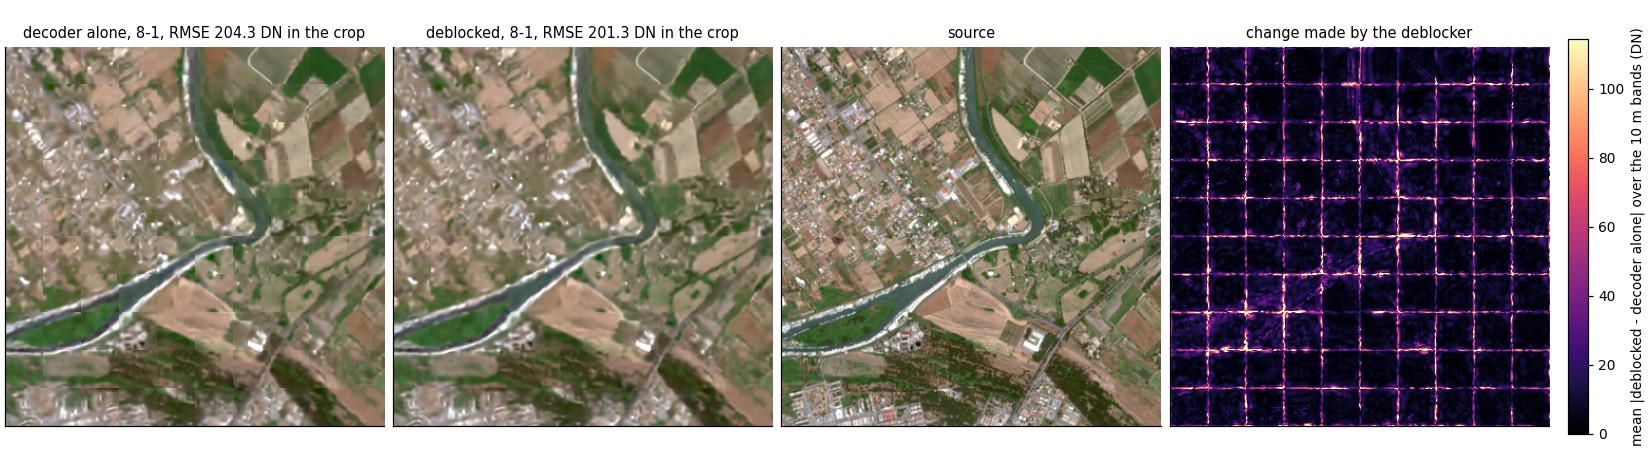

In [24]:
fig, ax = plt.subplots(1, 4, figsize=(15, 4.3), constrained_layout=True)
b10, d10 = dec["8-1"]["10m"][(slice(None),) + crop], db["8-1"]["10m"][(slice(None),) + crop]
for j, (k, a) in enumerate((("decoder alone, 8-1", b10), ("deblocked, 8-1", d10), ("source", ref10))):
    show(ax[j], st_true(a[TRUE]), crop_t, ticks=False)
    ax[j].set_title(k if k == "source" else f"{k}, RMSE {rmse(a, ref10):.1f} DN in the crop")
change = np.abs(d10.astype(np.float64) - b10).mean(0)
im = show(ax[3], change, crop_t, ticks=False, cmap="magma", vmin=0, vmax=np.percentile(change, 99))
ax[3].set_title("change made by the deblocker")
fig.colorbar(im, ax=ax[3], shrink=0.85, label="mean |deblocked - decoder alone| over the 10 m bands (DN)")
show_photo(fig)